# Thí nghiệm ablation: `OverallQual` có giải thích khoảng cách giữa RF của An và RF bộ sạch không?

Ở thí nghiệm trước, RF trên bộ feature sạch (80 feature) tốt hơn RF của An (feature `processed/`, 35 feature) khoảng 10%, và `OverallQual` chiếm hơn một nửa độ quan trọng, trong khi bộ của An **không có** `OverallQual`. Đó mới là suy luận. Notebook này kiểm chứng bằng cách thêm/bớt đúng một feature:

| Biến thể | Feature | Ý nghĩa |
|---|---|---|
| **A** | bộ của An (35 feature) | mốc so sánh |
| **B** | A **+ `OverallQual`** | thêm đúng 1 feature |
| **C** | bộ sạch (80 feature, bỏ `Id`) | mốc so sánh trên |
| **D** | C **− `OverallQual`** | bớt đúng 1 feature |

Tất cả: RF tham số mặc định, target `log1p(SalePrice)`, cùng phép chia train/valid và cùng 5 seed. Nếu `OverallQual` là nguyên nhân chính thì B phải gần C, và D phải gần A.

## Params

In [1]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]
TARGET_FEATURE = "OverallQual"

AN_RF_VALID_RMSE = 27713      # điểm An ghi trong baseline/baseline.ipynb

## import thư viện

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

## Đọc dữ liệu

Giống thí nghiệm Random Forest trước: bộ sạch đọc với `keep_default_na=False` (nhãn `None` không phải giá trị thiếu), bộ của An lấy từ `processed/`.

In [3]:
df = pd.read_csv("data/cleaned_data.csv", keep_default_na=False, na_values=[""])
ids = df["Id"]
df = df.drop(columns="Id")
X, y = df.drop(columns="SalePrice"), df["SalePrice"]

X_train, X_valid, y_train, y_valid, id_train, id_valid = train_test_split(
    X, y, ids, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train_log = np.log1p(y_train)

proc = Path("../../../data/processed")
Xp_train, Xp_valid = pd.read_csv(proc / "X_train.csv"), pd.read_csv(proc / "X_test.csv")
assert (y_train.values == pd.read_csv(proc / "y_train.csv")["SalePrice"].values).all()
assert (y_valid.values == pd.read_csv(proc / "y_test.csv")["SalePrice"].values).all()

# bộ của An là bản đã biến đổi, nên phải chắc chắn từng dòng khớp với dữ liệu sạch trước khi ghép thêm cột
for part, Xp, Xc in [("train", Xp_train, X_train), ("valid", Xp_valid, X_valid)]:
    corr = np.corrcoef(Xp["num__GrLivArea"].values, Xc["GrLivArea"].values)[0, 1]
    assert corr > 0.99999, (part, corr)
print("Bộ sạch:", X_train.shape, "| bộ của An:", Xp_train.shape, "| các dòng khớp nhau: OK")

Bộ sạch: (1166, 80) | bộ của An: (1166, 146) | các dòng khớp nhau: OK


## Bộ của An thiếu những feature gốc nào?

Bộ `processed/` đã One-Hot/Ordinal nên cột đã đổi tên; ở đây truy ngược về feature gốc để biết chính xác bộ của An bỏ gì.

In [4]:
def original_feature(col):
    name = col.split("__", 1)[1]
    matches = [f for f in X.columns if name == f or name.startswith(f + "_")]
    return max(matches, key=len)


an_features = sorted({original_feature(c) for c in Xp_train.columns})
missing_in_an = [c for c in X.columns if c not in an_features]
print(f"Bộ của An dùng {len(an_features)} feature gốc, thiếu {len(missing_in_an)} feature so với bộ sạch.")
print("Có OverallQual không:", TARGET_FEATURE in an_features)
print("Một số feature bị thiếu:", ", ".join(missing_in_an[:20]), "...")

Bộ của An dùng 35 feature gốc, thiếu 45 feature so với bộ sạch.
Có OverallQual không: False
Một số feature bị thiếu: Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Condition1, Condition2, OverallQual, OverallCond, YearBuilt, YearRemodAdd, RoofMatl, MasVnrType, Foundation, BsmtExposure, BsmtFinType1, BsmtFinSF1, BsmtFinType2, BsmtFinSF2 ...


## Dựng 4 biến thể

* A, B dùng bộ đã xử lý của An. Với B, thêm cột `OverallQual` thô (số nguyên 1–10); cây quyết định không phụ thuộc thang đo nên không cần scale.
* C, D dùng bộ sạch với cùng cách mã hóa như các thí nghiệm trước (Ordinal cho 9 cột chất lượng, One-Hot cho cột phân loại còn lại).

In [5]:
quality = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL = {
    "ExterQual": quality, "ExterCond": quality, "KitchenQual": quality, "HeatingQC": quality,
    "BsmtQual": ["No Basement"] + quality, "BsmtCond": ["No Basement"] + quality,
    "GarageQual": ["No Garage"] + quality, "GarageCond": ["No Garage"] + quality,
    "FireplaceQu": ["No Fireplace"] + quality,
}
NOMINAL_EXTRA = ["MSSubClass", "MoSold"]


def make_clean_rf(seed, columns):
    ordinal_cols = [c for c in ORDINAL if c in columns]
    nominal_cols = [c for c in columns if c not in ORDINAL and (c in NOMINAL_EXTRA or not pd.api.types.is_numeric_dtype(X[c]))]
    numeric_cols = [c for c in columns if c not in ordinal_cols + nominal_cols]
    encoder = ColumnTransformer(
        [
            ("ordinal", OrdinalEncoder(categories=[ORDINAL[c] for c in ordinal_cols],
                                       handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", "passthrough", numeric_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("encoder", encoder), ("rf", RandomForestRegressor(random_state=seed))])


def make_plain_rf(seed, columns=None):
    return RandomForestRegressor(random_state=seed)


Xb_train = pd.concat([Xp_train, X_train[[TARGET_FEATURE]].reset_index(drop=True)], axis=1)
Xb_valid = pd.concat([Xp_valid, X_valid[[TARGET_FEATURE]].reset_index(drop=True)], axis=1)
clean_minus = [c for c in X.columns if c != TARGET_FEATURE]

VARIANTS = {
    "A. Bộ của An": (Xp_train, Xp_valid, make_plain_rf),
    "B. A + OverallQual": (Xb_train, Xb_valid, make_plain_rf),
    "C. Bộ sạch": (X_train, X_valid, lambda seed: make_clean_rf(seed, list(X.columns))),
    "D. Bộ sạch − OverallQual": (X_train[clean_minus], X_valid[clean_minus], lambda seed: make_clean_rf(seed, clean_minus)),
}
for name, (Xtr, Xva, _) in VARIANTS.items():
    print(f"{name:28s} {Xtr.shape[1]:4d} cột")

A. Bộ của An                  146 cột
B. A + OverallQual            147 cột
C. Bộ sạch                     80 cột
D. Bộ sạch − OverallQual       79 cột


## Cách chấm điểm

Mô hình học trên `log1p(SalePrice)`, dự đoán đổi về USD bằng `expm1`. **RMSE (USD)** là chỉ số An dùng; **RMSLE** là chỉ số Kaggle (RMSE trên thang log).

In [6]:
def evaluate(y_true, pred_log):
    pred = np.expm1(pred_log)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "MAE": mean_absolute_error(y_true, pred),
        "R2": r2_score(y_true, pred),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), pred_log)),
    }

## Run 1 – Điểm của 4 biến thể trên 5 seed

Mỗi biến thể được huấn luyện 5 lần (5 seed) để có độ dao động; so sánh theo cặp vì mọi biến thể dùng cùng seed và cùng dữ liệu.

In [7]:
rows, models_seed42 = [], {}
for name, (Xtr, Xva, builder) in VARIANTS.items():
    for seed in SEEDS:
        model = builder(seed).fit(Xtr, y_train_log)
        r = evaluate(y_valid, model.predict(Xva))
        rows.append({"biến thể": name, "seed": seed, **{k: r[k] for k in ["RMSE", "RMSLE", "R2"]}})
    models_seed42[name] = builder(RANDOM_STATE).fit(Xtr, y_train_log)

seeds_df = pd.DataFrame(rows)
summary = seeds_df.groupby("biến thể")[["RMSE", "RMSLE", "R2"]].agg(["mean", "std"])
summary.round(4)

RMSE             RMSLE              R2        
                                mean       std    mean     std    mean     std
biến thể                                                                      
A. Bộ của An              27333.2581  273.7514  0.1552  0.0016  0.8647  0.0027
B. A + OverallQual        25537.4812  313.2225  0.1488  0.0019  0.8819  0.0029
C. Bộ sạch                24359.9419  375.0360  0.1436  0.0016  0.8926  0.0033
D. Bộ sạch − OverallQual  24441.5405  417.9870  0.1443  0.0013  0.8918  0.0037

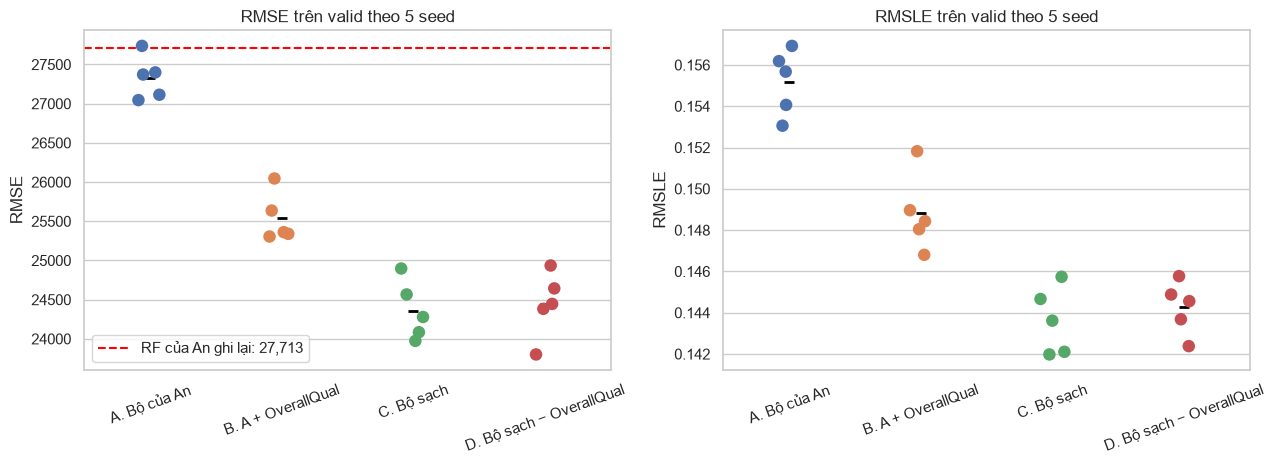

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axes, ["RMSE", "RMSLE"]):
    sns.stripplot(data=seeds_df, x="biến thể", y=metric, hue="biến thể", s=9, ax=ax, legend=False)
    sns.pointplot(data=seeds_df, x="biến thể", y=metric, linestyle="none", color="black", markers="_", errorbar=None, ax=ax)
    ax.set_title(f"{metric} trên valid theo 5 seed")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
axes[0].axhline(AN_RF_VALID_RMSE, color="red", linestyle="--", label=f"RF của An ghi lại: {AN_RF_VALID_RMSE:,}")
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/rf_ablation_seed_compare.png", dpi=150)
plt.show()

**Nhận xét:**

| Biến thể | RMSE TB (USD) | RMSLE TB |
|---|---|---|
| A. Bộ của An | 27.333 | 0,1552 |
| B. A + `OverallQual` | 25.537 | 0,1488 |
| C. Bộ sạch | 24.360 | 0,1436 |
| D. Bộ sạch − `OverallQual` | 24.442 | 0,1443 |

- **A → B:** chỉ thêm đúng `OverallQual` đã giảm RMSE trung bình 1.796 USD (6,6%); các điểm của B nằm hoàn toàn dưới các điểm của A (không chồng nhau).
- **C → D:** bỏ `OverallQual` khỏi bộ sạch gần như không làm kém đi: RMSE tăng 82 USD, nhỏ hơn độ lệch chuẩn theo seed (375 đến 418), hai khoảng chồng nhau.
- B vẫn kém C khoảng 1.177 USD (4,8%), nghĩa là còn một phần khoảng cách không đến từ `OverallQual`.
- Lưu ý nhỏ: RMSE của C ở đây (24.360) lệch 29 USD so với thí nghiệm RF trước (24.389) vì thứ tự cột sau mã hóa khác nên các cây được chọn feature ngẫu nhiên khác đi; chênh lệch này rất nhỏ so với độ lệch chuẩn theo seed.

## Run 2 – Phần khoảng cách được giải thích bởi `OverallQual`

* Khoảng cách A → C là tổng mức cải thiện của bộ sạch so với bộ của An.
* B cho biết thêm **riêng `OverallQual`** vào A thu hồi được bao nhiêu phần của khoảng cách đó.
* D cho biết bỏ **riêng `OverallQual`** khỏi bộ sạch làm mất bao nhiêu.

In [9]:
mean_rmse = seeds_df.groupby("biến thể")["RMSE"].mean()
mean_rmsle = seeds_df.groupby("biến thể")["RMSLE"].mean()
A, B, C, D = (mean_rmse[k] for k in VARIANTS)
La, Lb, Lc, Ld = (mean_rmsle[k] for k in VARIANTS)

# so sánh theo cặp seed: chênh lệch RMSE so với A, từng seed
pivot = seeds_df.pivot(index="seed", columns="biến thể", values="RMSE")
paired = pivot.sub(pivot["A. Bộ của An"], axis=0).drop(columns="A. Bộ của An")

gap = pd.DataFrame({
    "RMSE TB (USD)": mean_rmse,
    "RMSLE TB": mean_rmsle,
    "RMSE chênh so với A (USD)": mean_rmse - A,
    "RMSE chênh so với A (%)": (mean_rmse / A - 1) * 100,
})
print(f"Khoảng cách A → C (RMSE): {A - C:,.0f} USD ({(A - C) / A:.1%})")
print(f"Thêm riêng OverallQual vào A (B) thu hồi: {(A - B) / (A - C):.0%} khoảng cách (RMSE), {(La - Lb) / (La - Lc):.0%} (RMSLE)")
print(f"Bỏ riêng OverallQual khỏi bộ sạch (D) làm mất: {(D - C) / (A - C):.0%} khoảng cách (RMSE), {(Ld - Lc) / (La - Lc):.0%} (RMSLE)")
print("Số seed mà biến thể tốt hơn A:", (paired < 0).sum().to_dict())
gap.round({"RMSE TB (USD)": 0, "RMSLE TB": 4, "RMSE chênh so với A (USD)": 0, "RMSE chênh so với A (%)": 1})

Khoảng cách A → C (RMSE): 2,973 USD (10.9%)
Thêm riêng OverallQual vào A (B) thu hồi: 60% khoảng cách (RMSE), 55% (RMSLE)
Bỏ riêng OverallQual khỏi bộ sạch (D) làm mất: 3% khoảng cách (RMSE), 5% (RMSLE)
Số seed mà biến thể tốt hơn A: {'B. A + OverallQual': 5, 'C. Bộ sạch': 5, 'D. Bộ sạch − OverallQual': 5}


,RMSE TB (USD),RMSLE TB,RMSE chênh so với A (USD),RMSE chênh so với A (%)
biến thể,,,,
A. Bộ của An,27333.0,0.1552,0.0,0.0
B. A + OverallQual,25537.0,0.1488,-1796.0,-6.6
C. Bộ sạch,24360.0,0.1436,-2973.0,-10.9
D. Bộ sạch − OverallQual,24442.0,0.1443,-2892.0,-10.6


**Nhận xét:**
- Bộ sạch tốt hơn bộ của An 2.973 USD (10,9%) theo RMSE.
- **Thêm riêng `OverallQual` vào bộ của An thu hồi khoảng 60% khoảng cách này** theo RMSE (55% theo RMSLE).
- **Bỏ riêng `OverallQual` khỏi bộ sạch chỉ làm mất khoảng 3%** (5% theo RMSLE).
- Cả B, C, D đều tốt hơn A ở 5/5 seed.
- Hai kết quả trên không mâu thuẫn mà bổ sung cho nhau: `OverallQual` **đủ** để giải thích phần lớn khoảng cách khi bộ của An thiếu nó, nhưng **không bắt buộc** khi đã có đủ 80 feature, vì bộ sạch còn các feature khác (ví dụ `OverallCond`, `YearBuilt`, `1stFlrSF`) có khả năng mang thông tin tương tự. Giải thích này là suy luận, chưa được kiểm chứng riêng.
- Khoảng 40% khoảng cách còn lại (từ B đến C) đến từ 44 feature khác mà bộ của An không có; thí nghiệm này chưa tách ra feature nào trong số đó.

## Run 3 – Cross-validation 5-fold trên tập train

Tập valid chỉ có 292 dòng nên kiểm tra lại bằng CV trên 1.166 dòng train (RMSLE).

In [10]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, (Xtr, Xva, builder) in VARIANTS.items():
    cv_scores[name] = -cross_val_score(builder(RANDOM_STATE), Xtr, y_train_log, cv=cv, scoring="neg_root_mean_squared_error")

cv_df = pd.DataFrame(cv_scores, index=[f"fold {i + 1}" for i in range(CV_FOLDS)])
cv_df.loc["trung bình"] = cv_df.mean()
cv_df.loc["độ lệch chuẩn"] = cv_df.iloc[:CV_FOLDS].std()
folds_better = {k: int((cv_df.iloc[:CV_FOLDS][k] < cv_df.iloc[:CV_FOLDS]["A. Bộ của An"]).sum()) for k in list(VARIANTS)[1:]}
print("Số fold (trên 5) mà biến thể có RMSLE thấp hơn A:", folds_better)
cv_df.round(4)

Số fold (trên 5) mà biến thể có RMSLE thấp hơn A: {'B. A + OverallQual': 5, 'C. Bộ sạch': 5, 'D. Bộ sạch − OverallQual': 5}


,A. Bộ của An,B. A + OverallQual,C. Bộ sạch,D. Bộ sạch − OverallQual
fold 1,0.1741,0.1619,0.1557,0.1597
fold 2,0.1538,0.1474,0.1401,0.1436
fold 3,0.1420,0.1406,0.1281,0.1296
fold 4,0.1344,0.1335,0.1309,0.1264
fold 5,0.1583,0.1538,0.1447,0.1475
trung bình,0.1525,0.1475,0.1399,0.1414
độ lệch chuẩn,0.0153,0.0111,0.0111,0.0136


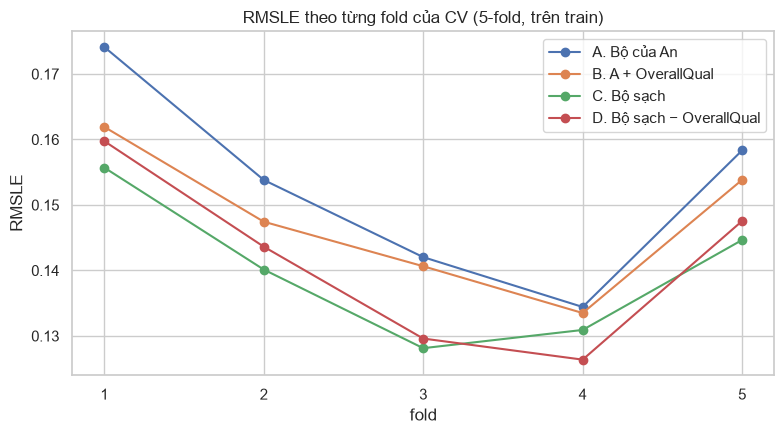

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in VARIANTS:
    ax.plot(range(1, CV_FOLDS + 1), cv_df.iloc[:CV_FOLDS][name], marker="o", label=name)
ax.set_xticks(range(1, CV_FOLDS + 1))
ax.set_xlabel("fold")
ax.set_ylabel("RMSLE")
ax.set_title("RMSLE theo từng fold của CV (5-fold, trên train)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/rf_ablation_cv_folds.png", dpi=150)
plt.show()

**Nhận xét:**
- RMSLE CV trung bình: A 0,1525, B 0,1475, C 0,1399, D 0,1414. B, C, D đều tốt hơn A ở **5/5 fold**, cùng chiều với tập valid.
- Về độ lớn thì CV cho bức tranh khiêm tốn hơn valid: thêm `OverallQual` vào A thu hồi khoảng **40%** khoảng cách A → C (0,0050 trên 0,0126), thay vì 55–60% trên valid; bỏ `OverallQual` khỏi bộ sạch làm mất khoảng 12% (0,0015). Ở fold 3 và fold 4, B chỉ hơn A 0,0014 và 0,0009.
- Độ lệch chuẩn giữa các fold (0,011 đến 0,015) lớn hơn nhiều chênh lệch A–B (0,005), nên con số "bao nhiêu phần trăm" không nên đọc quá chính xác. Kết luận chắc chắn chỉ là hướng: `OverallQual` giải thích **một phần đáng kể (khoảng 40–60%)**, không phải toàn bộ khoảng cách.

## Độ quan trọng của `OverallQual` khi được thêm vào bộ của An

In [12]:
model_b = models_seed42["B. A + OverallQual"]
imp_b = pd.Series(model_b.feature_importances_, index=Xb_train.columns).sort_values(ascending=False)
imp_a = pd.Series(models_seed42["A. Bộ của An"].feature_importances_, index=Xp_train.columns).sort_values(ascending=False)

print("Top 5 của A:", imp_a.head(5).round(3).to_dict())
print("Top 5 của B:", imp_b.head(5).round(3).to_dict())
imp_b.head(10).round(4).to_frame("importance (B)")

Top 5 của A: {'ord__ExterQual': 0.335, 'num__GrLivArea': 0.217, 'num__TotalBsmtSF': 0.092, 'num__GarageArea': 0.082, 'ord__KitchenQual': 0.042}
Top 5 của B: {'OverallQual': 0.524, 'num__GrLivArea': 0.125, 'num__TotalBsmtSF': 0.077, 'num__GarageArea': 0.071, 'num__GarageCars': 0.029}


,importance (B)
OverallQual,0.5241
num__GrLivArea,0.1254
num__TotalBsmtSF,0.0767
num__GarageArea,0.0709
num__GarageCars,0.0286
num__LotArea,0.0199
bin__CentralAir_Y,0.0182
ord__BsmtQual,0.0126
num__LotFrontage,0.0073
ord__KitchenQual,0.0071


**Nhận xét:**
- Khi được thêm vào bộ của An, `OverallQual` lập tức chiếm **52,4%** độ quan trọng (gần bằng 51,7% trong bộ sạch), và `GrLivArea` giảm từ 21,7% xuống 12,5%.
- `ExterQual`, feature quan trọng nhất của bộ A (33,5%), rơi khỏi top 10 của B (dưới 0,7%). Điều này cho thấy trong bộ của An, `ExterQual` đang đóng vai trò thay thế cho `OverallQual`, và RF dùng `OverallQual` là thông tin chất lượng tốt hơn.

# Lưu kết quả

Lưu tham số, model biến thể B (A + `OverallQual`), dự đoán valid của 4 biến thể (seed 42) và nhật ký Excel `Working_details_RF_Ablation_OverallQual.xlsx`.

In [13]:
params = model_b.get_params()
with open("random_forest_ablation_params.json", "w", encoding="utf-8") as f:
    json.dump({"model_params": params, "variant": "B. A + OverallQual", "feature_names": list(Xb_train.columns)},
              f, indent=4, ensure_ascii=False)

joblib.dump(model_b, "random_forest_ablation_model.pkl", compress=3)

pred = {"Id": id_valid.values, "SalePrice": y_valid.values}
for name, (Xtr, Xva, builder) in VARIANTS.items():
    pred[name.split(".")[0]] = np.expm1(models_seed42[name].predict(Xva))
pd.DataFrame(pred).to_csv("data/valid_predictions.csv", index=False)
print("Đã lưu params, model B, dự đoán valid của 4 biến thể")

Đã lưu params, model B, dự đoán valid của 4 biến thể


In [14]:
import zipfile
from xml.sax.saxutils import escape


def col_letter(i):
    s = ""
    i += 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s


def write_xlsx(path, sheet_name, rows, header_rows, widths):
    """Ghi 1 sheet Excel tối giản (chuỗi + số), header_rows là chỉ số dòng (0-based) cần in đậm."""
    xml_rows = []
    for r, row in enumerate(rows):
        cells = []
        for c, v in enumerate(row):
            if v is None or v == "":
                continue
            ref = f"{col_letter(c)}{r + 1}"
            style = ' s="1"' if r in header_rows else ""
            if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
                cells.append(f'<c r="{ref}"{style}><v>{float(v)}</v></c>')
            else:
                cells.append(f'<c r="{ref}"{style} t="inlineStr"><is><t xml:space="preserve">{escape(str(v))}</t></is></c>')
        xml_rows.append(f'<row r="{r + 1}">{"".join(cells)}</row>')
    cols = "".join(f'<col min="{i + 1}" max="{i + 1}" width="{w}" customWidth="1"/>' for i, w in enumerate(widths))
    sheet = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
             '<worksheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
             f'<cols>{cols}</cols><sheetData>{"".join(xml_rows)}</sheetData></worksheet>')
    styles = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
              '<styleSheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
              '<fonts count="2"><font><sz val="11"/><name val="Calibri"/></font>'
              '<font><b/><sz val="11"/><name val="Calibri"/></font></fonts>'
              '<fills count="3"><fill><patternFill patternType="none"/></fill><fill><patternFill patternType="gray125"/></fill>'
              '<fill><patternFill patternType="solid"><fgColor rgb="FFD9E1F2"/></patternFill></fill></fills>'
              '<borders count="1"><border><left/><right/><top/><bottom/><diagonal/></border></borders>'
              '<cellStyleXfs count="1"><xf numFmtId="0" fontId="0" fillId="0" borderId="0"/></cellStyleXfs>'
              '<cellXfs count="2"><xf numFmtId="0" fontId="0" fillId="0" borderId="0" xfId="0"/>'
              '<xf numFmtId="0" fontId="1" fillId="2" borderId="0" xfId="0" applyFont="1" applyFill="1"/></cellXfs>'
              '</styleSheet>')
    files = {
        "[Content_Types].xml": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/xl/workbook.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.sheet.main+xml"/><Override PartName="/xl/worksheets/sheet1.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.worksheet+xml"/><Override PartName="/xl/styles.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.styles+xml"/></Types>',
        "_rels/.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/officeDocument" Target="xl/workbook.xml"/></Relationships>',
        "xl/workbook.xml": f'<?xml version="1.0" encoding="UTF-8" standalone="yes"?><workbook xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main" xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships"><sheets><sheet name="{escape(sheet_name)}" sheetId="1" r:id="rId1"/></sheets></workbook>',
        "xl/_rels/workbook.xml.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/worksheet" Target="worksheets/sheet1.xml"/><Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/styles" Target="styles.xml"/></Relationships>',
        "xl/styles.xml": styles,
        "xl/worksheets/sheet1.xml": sheet,
    }
    with zipfile.ZipFile(path, "w", zipfile.ZIP_DEFLATED) as z:
        for name, content in files.items():
            z.writestr(name, content)

In [15]:
rows, headers = [], set()


def add(row, header=False):
    if header:
        headers.add(len(rows))
    rows.append(row)


add(["THÍ NGHIỆM ABLATION RANDOM FOREST — VAI TRÒ CỦA OverallQual"], header=True)
add(["Trạng thái", "Đã chạy; điểm tính trên tập valid tự chia, chưa nộp Kaggle"])
add([])
add(["Thiết lập", "Giá trị"], header=True)
add(["Mô hình", "RandomForestRegressor, tham số mặc định (n_estimators=100)"])
add(["Target", "log1p(SalePrice), dự đoán đổi về USD bằng expm1"])
add(["Chia dữ liệu", f"train {len(X_train)} / valid {len(X_valid)} (80/20, seed {RANDOM_STATE}), giống RF của An"])
add(["Seed", ", ".join(map(str, SEEDS)) + f" (CV dùng seed {RANDOM_STATE})"])
add(["Biến thể", "A: bộ của An | B: A + OverallQual | C: bộ sạch | D: C - OverallQual"])
add(["Số cột", ", ".join(f"{k.split('.')[0]}={v[0].shape[1]}" for k, v in VARIANTS.items())])
add([])
add(["1. Kết quả theo biến thể (5 seed)"], header=True)
add(["Biến thể", "RMSE TB (USD)", "RMSE độ lệch chuẩn", "RMSLE TB", "RMSLE CV 5-fold", "RMSE chênh so với A (%)"], header=True)
for name in VARIANTS:
    add([name, round(summary.loc[name, ("RMSE", "mean")], 0), round(summary.loc[name, ("RMSE", "std")], 0),
         round(summary.loc[name, ("RMSLE", "mean")], 4), round(cv_df.loc["trung bình", name], 4),
         round((mean_rmse[name] / A - 1) * 100, 1)])
add([])
add(["2. Phần khoảng cách A → C được giải thích bởi OverallQual"], header=True)
add(["Chỉ tiêu", "RMSE", "RMSLE"], header=True)
add(["Khoảng cách A → C", round(A - C, 0), round(La - Lc, 4)])
add(["Thêm riêng OverallQual vào A (B) thu hồi", f"{(A - B) / (A - C):.0%}", f"{(La - Lb) / (La - Lc):.0%}"])
add(["Bỏ riêng OverallQual khỏi C (D) làm mất", f"{(D - C) / (A - C):.0%}", f"{(Ld - Lc) / (La - Lc):.0%}"])
add([])
add(["3. Điểm theo từng seed (valid)"], header=True)
add(["Seed", "Biến thể", "RMSE", "RMSLE", "R2"], header=True)
for _, r in seeds_df.iterrows():
    add([int(r["seed"]), r["biến thể"], round(r["RMSE"], 0), round(r["RMSLE"], 4), round(r["R2"], 4)])
add([])
add(["4. Cross-validation 5-fold (RMSLE trên train)"], header=True)
add([""] + list(VARIANTS), header=True)
for idx, r in cv_df.iterrows():
    add([idx] + [round(float(r[k]), 4) for k in VARIANTS])
add([])
add(["5. Top 10 feature quan trọng của B (A + OverallQual)"], header=True)
add(["Feature", "Importance"], header=True)
for name, v in imp_b.head(10).items():
    add([name, round(float(v), 4)])

write_xlsx("Working_details_RF_Ablation_OverallQual.xlsx", "RF_Ablation_OverallQual", rows, headers, [44, 24, 22, 28, 28, 26])
print("Đã ghi Working_details_RF_Ablation_OverallQual.xlsx")

Đã ghi Working_details_RF_Ablation_OverallQual.xlsx
